# Exploratory Data Analysis of Google Play Store Applications
### Minor Project 02 (CA 03) — CSB314 | UNIT IV and UNIT V

**Dataset:** Google Play Store Apps (`googleplaystore.csv`)  
**Kaggle source:** https://www.kaggle.com/datasets/lava18/google-play-store-apps  
**Dataset grain:** One row is intended to represent one app listing. The supplied file contains 10,841 rows and 13 columns.  
**Central analytical question:** What patterns in category, price, installs, ratings, app size and content rating characterise the Google Play Store app listings in this dataset?

> **Reproducibility and source note:** This notebook uses the CSV supplied with the project. The companion `googleplaystore_user_reviews.csv` and `license.txt` listed on the Kaggle page were not supplied. Therefore, no user-review sentiment analysis is claimed. A category dimension is derived from the supplied app table for integration demonstrations. Controlled distribution examples are explicitly labelled as simulations and are never described as original app observations. Confirm the current Kaggle licence and terms on the source page before reuse.

## Notebook roadmap
1. Project Title and Introduction
2. Problem Statement and Analytical Objectives
3. Dataset Source and Description
4. Importing Libraries and Loading Data
5. Dataset Understanding
6. Data Quality Assessment
7. Feature Engineering
8. Grouping and Aggregation
9. Pivot Tables and Crosstab
10. Data Reshaping
11. Data Integration
12. Descriptive Statistics
13. Distribution Analysis
14. Empirical Rule
15. Sampling and Central Limit Theorem
16. Correlation Analysis
17. Outlier Detection and Treatment
18. Data Visualisation and Interpretation
19. Findings and Observations
20. Limitations and Future Scope
21. Final Conclusion

## 1. Project Title and Introduction
Exploratory Data Analysis (EDA) is the process of examining a dataset using summaries and visualisations before drawing conclusions or building models. This project applies the Pandas feature-engineering, grouping, aggregation, reshaping and integration concepts from Unit IV, followed by statistical and distribution analysis from Unit V.

The app dataset contains numerical fields (rating, reviews, size after parsing, installs and price), categorical fields (category, type, content rating and genres), and a date field (`Last Updated`). These support a broad app-listing analysis.

## 2. Problem Statement and Analytical Objectives
### Problem statement
The raw app listing data contains mixed data types, missing values, repeated app names and text-formatted numerical fields. These issues must be assessed and handled transparently before meaningful comparisons can be made.

### Analytical objectives
- Engineer at least four meaningful variables from existing columns.
- Compare app listings across categories and other categorical groups.
- Demonstrate `groupby()`, `agg()`, `transform()`, pivot tables and crosstabulation.
- Demonstrate wide/long reshaping using `melt()`, `pivot()`, `stack()` and `unstack()`.
- Integrate related/derived tables with `merge()`, `join()` and `concat()` while validating keys and row counts.
- Calculate central tendency, dispersion, quantiles, skewness and kurtosis.
- Explore distribution shapes, the empirical rule, sampling variability and the Central Limit Theorem.
- Measure associations using covariance, Pearson and Spearman correlation.
- Detect potential outliers using IQR and Z-scores and compare handling strategies.
- Assess completeness, consistency, plausibility, duplicates, validity and key integrity.

## 3. Dataset Source and Description
- **Dataset name:** Google Play Store Apps and Reviews.
- **Kaggle URL:** https://www.kaggle.com/datasets/lava18/google-play-store-apps
- **Downloaded file provided for this notebook:** `googleplaystore.csv`.
- **Kaggle page lists:** `googleplaystore.csv`, `googleplaystore_user_reviews.csv` and `license.txt`.
- **Key columns:** `App` (app name), `Category`, `Rating`, `Reviews`, `Size`, `Installs`, `Type`, `Price`, `Content Rating`, `Genres`, `Last Updated`, `Current Ver`, `Android Ver`.
- **Expected relationship in full Kaggle dataset:** app name links the apps and reviews tables; one app may have many review records. App names should be checked for spelling inconsistencies and duplicates before merging.
- **Licence/usage:** the licence text file was not included in the supplied files. Its conditions cannot be verified here; check the licence displayed on the Kaggle source page before redistribution or reuse.

### Table grain and integration caution
The supplied apps file is app-listing-level. Repeated `App` values may be duplicate listings or inconsistent records and must be investigated rather than blindly removed. The reviews table is absent, so this notebook does not invent review records or claim app-review integration.

## 4. Importing Libraries and Loading Data
### Objective and methodology
Use Pandas for tabular work, NumPy for numerical operations, Matplotlib and Seaborn for plots. A fixed seed is used for all sampling and controlled simulations. The raw DataFrame is retained unchanged; all cleaning and engineering occur in separate working copies.

In [2]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
plt.style.use("ggplot")

# Keep googleplaystore.csv beside this notebook, or place it in data/ or datasets/.
csv_name = "googleplaystore.csv"
search_locations = [
    Path.cwd() / csv_name,
    Path.cwd() / "data" / csv_name,
    Path.cwd() / "dataset" / csv_name,
    Path.cwd() / "datasets" / csv_name,
    Path.cwd().parent / csv_name,
    Path("/mnt/data") / csv_name,
]
DATA_PATH = next((str(p.resolve()) for p in search_locations if p.is_file()), None)

# If the notebook is launched from a project folder, search its immediate subfolders too.
if DATA_PATH is None:
    for folder in [Path.cwd(), Path.cwd() / "data", Path.cwd() / "dataset", Path.cwd() / "datasets"]:
        if folder.is_dir():
            match = next((p for p in folder.glob("**/" + csv_name) if p.is_file()), None)
            if match is not None:
                DATA_PATH = str(match.resolve())
                break

if DATA_PATH is None:
    raise FileNotFoundError(
        "Cannot find googleplaystore.csv. Put it in the same folder as this notebook "
        "or inside a data/ or datasets/ folder, then run this cell again."
    )

raw_df = pd.read_csv(DATA_PATH)
apps = raw_df.copy(deep=True)  # Keep raw_df unchanged; work on apps.
print("Loaded dataset:", DATA_PATH)
print("Dataset shape:", raw_df.shape)
display(raw_df.head())

Loaded dataset: /home/workspace/my-project/googleplaystore.csv
Dataset shape: (10841, 13)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


## 5. Dataset Understanding
### Subtask 5.1 — Structure, dimensions and sample records
**Objective:** Understand the number of records, variables and their initial representation.  
**Concept/method:** `shape`, `head`, `tail`, `info` and `describe` provide structural and preliminary numerical summaries.  
**Interpretation/observations:** The outputs below are generated from the supplied CSV and should be reviewed before transformation.

In [3]:
# If this cell is run before the loading cell, load the CSV here as a safety fallback.
if "raw_df" not in globals():
    from pathlib import Path
    import pandas as pd
    from IPython.display import display

    fallback_candidates = [
        Path.cwd() / "googleplaystore.csv",
        Path.cwd() / "data" / "googleplaystore.csv",
        Path.cwd() / "dataset" / "googleplaystore.csv",
        Path.cwd() / "datasets" / "googleplaystore.csv",
        Path.cwd().parent / "googleplaystore.csv",
        Path("/mnt/data/googleplaystore.csv"),
    ]
    fallback_path = next((p for p in fallback_candidates if p.is_file()), None)
    if fallback_path is None:
        raise FileNotFoundError(
            "googleplaystore.csv was not found. Place it beside the notebook "
            "or in a data/ or datasets/ folder, then run the loading cell."
        )
    DATA_PATH = str(fallback_path.resolve())
    raw_df = pd.read_csv(DATA_PATH)
    apps = raw_df.copy(deep=True)

print("Shape:", raw_df.shape)
print("\\nColumn names:", raw_df.columns.tolist())
print("\\nData types:")
display(raw_df.dtypes.rename("data_type").to_frame())
print("\\nInfo:")
raw_df.info()
print("\\nFirst five rows:")
display(raw_df.head())
print("\\nLast five rows:")
display(raw_df.tail())
print("\\nNumerical summary:")
display(raw_df.describe(include="all").T)

Shape: (10841, 13)
\nColumn names: ['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']
\nData types:


,data_type
App,str
Category,str
Rating,float64
Reviews,str
Size,str
Installs,str
Type,str
Price,str
Content Rating,str
Genres,str


\nInfo:
<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB
\nFirst five rows:


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


\nLast five rows:


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10836,Sya9a Maroc - FR,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education,"July 25, 2017",1.48,4.1 and up
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education,"July 6, 2018",1.0,4.1 and up
10838,Parkinson Exercices FR,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical,"January 20, 2017",1.0,2.2 and up
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference,"January 19, 2015",Varies with device,Varies with device
10840,iHoroscope - 2018 Daily Horoscope & Astrology,LIFESTYLE,4.5,398307,19M,"10,000,000+",Free,0,Everyone,Lifestyle,"July 25, 2018",Varies with device,Varies with device


\nNumerical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
App,10841,9660,ROBLOX,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,10841,34,FAMILY,1972,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9367.0,NaN,NaN,NaN,4.193338,0.537431,1.0,4.0,4.3,4.5,19.0
Reviews,10841,6002,0,596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Size,10841,462,Varies with device,1695,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Installs,10841,22,"1,000,000+",1579,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10840,3,Free,10039,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,10841,93,0,10040,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Content Rating,10840,6,Everyone,8714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Genres,10841,120,Tools,842,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Subtask 5.2 — Identify variable roles and table grain
`App` is the natural candidate identifier, but duplicate app names exist and must be investigated. `Category`, `Type`, `Content Rating` and `Genres` are categorical. `Rating` is numeric, while `Reviews`, `Size`, `Installs` and `Price` are numeric concepts stored as text. `Last Updated` is a date stored as text. `Current Ver` and `Android Ver` are version strings, not ordinary continuous measurements.

**Decision:** Parse numerical/date fields into new columns, preserving the original raw strings for traceability.

In [4]:
variable_roles = pd.DataFrame({
    "Column": raw_df.columns,
    "Role": [
        "Identifier / text", "Categorical", "Numerical", "Numerical stored as text",
        "Size measurement stored as text", "Numerical stored as text",
        "Categorical", "Currency stored as text", "Categorical", "Categorical",
        "Date stored as text", "Version string", "Version/compatibility string"
    ]
})
display(variable_roles)
print("Unique app names:", raw_df["App"].nunique())
print("Repeated app-name rows:", raw_df["App"].duplicated(keep=False).sum())

,Column,Role
0,App,Identifier / text
1,Category,Categorical
2,Rating,Numerical
3,Reviews,Numerical stored as text
4,Size,Size measurement stored as text
5,Installs,Numerical stored as text
6,Type,Categorical
7,Price,Currency stored as text
8,Content Rating,Categorical
9,Genres,Categorical


Unique app names: 9660
Repeated app-name rows: 1979


## 6. Data Quality Assessment
This section covers the seven required dimensions: completeness, consistency, accuracy/plausibility, duplicates, validity/data types, key integrity and integration quality. Missingness is quantified before any decisions. Duplicate names are not automatically dropped because they may represent conflicting app records.

### Task 17 — Data Quality Checks
#### Subtask 17.1 — Completeness
**Objective:** Count missing values and calculate missing percentages by column.  
**Method:** `isna().sum()` and percentage of total rows.  
**Decision:** Missing ratings remain missing; they are not filled with an invented rating.

,missing_count,missing_percent
Rating,1474,13.60
Current Ver,8,0.07
Android Ver,3,0.03
Type,1,0.01
Content Rating,1,0.01
App,0,0.00
Category,0,0.00
Reviews,0,0.00
Size,0,0.00
Installs,0,0.00


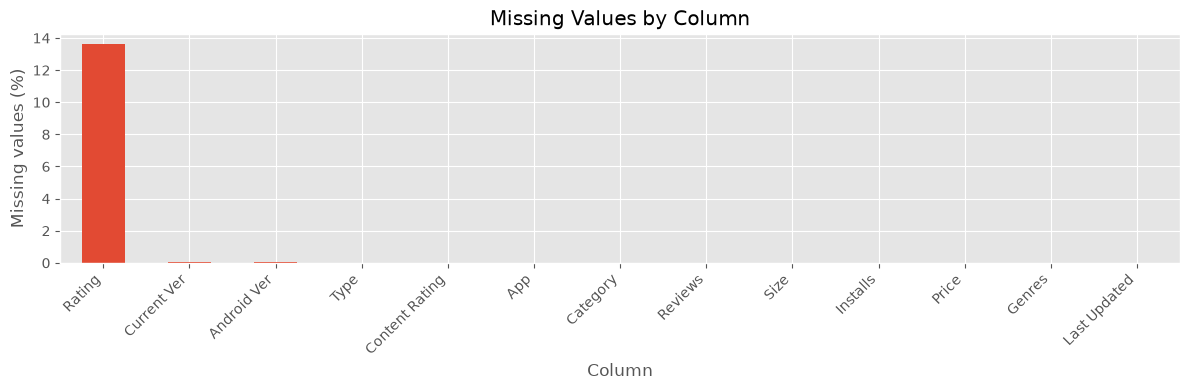

Observation 1: Columns at the top of the table have the greatest missingness.
Observation 2: Missing ratings can reduce the usable sample for rating-specific analyses; missing categorical values affect grouping.


In [5]:
missing_report = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_percent": (raw_df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
display(missing_report)
plt.figure(figsize=(12, 4))
missing_report["missing_percent"].sort_values(ascending=False).plot(kind="bar")
plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Missing values (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
print("Observation 1: Columns at the top of the table have the greatest missingness.")
print("Observation 2: Missing ratings can reduce the usable sample for rating-specific analyses; missing categorical values affect grouping.")

#### Subtask 17.2 — Consistency
Check category spelling/case, repeated labels and whitespace. The report displays the most frequent raw labels. Normalisation is performed only on working columns where it is safe (leading/trailing whitespace); original values remain available in `raw_df`.

In [48]:
for col in ["Category", "Type", "Content Rating", "Genres"]:
    print(f"\\n{col}: {raw_df[col].nunique(dropna=True)} distinct non-null labels")
    display(raw_df[col].value_counts(dropna=False).head(12).rename("count").to_frame())

\nCategory: 34 distinct non-null labels


,count
Category,
FAMILY,1972
GAME,1144
TOOLS,843
MEDICAL,463
BUSINESS,460
PRODUCTIVITY,424
PERSONALIZATION,392
COMMUNICATION,387
SPORTS,384


\nType: 3 distinct non-null labels


,count
Type,
Free,10039
Paid,800
NaN,1
0,1


\nContent Rating: 6 distinct non-null labels


,count
Content Rating,
Everyone,8714
Teen,1208
Mature 17+,499
Everyone 10+,414
Adults only 18+,3
Unrated,2
NaN,1


\nGenres: 120 distinct non-null labels


,count
Genres,
Tools,842
Entertainment,623
Education,549
Medical,463
Business,460
Productivity,424
Sports,398
Personalization,392
Communication,387


#### Subtask 17.3 — Accuracy and plausibility
Domain checks include ratings outside 1–5, negative review counts, negative prices, invalid install counts, and unparseable dates. A malformed row can shift values across columns; inspect suspicious rows before making a correction. The known row with a category-like value in `Rating` is flagged by the numeric conversion and plausibility checks rather than silently repaired.

In [6]:
quality_probe = raw_df.copy()
quality_probe["Rating_num"] = pd.to_numeric(quality_probe["Rating"], errors="coerce")
quality_probe["Reviews_num"] = pd.to_numeric(quality_probe["Reviews"], errors="coerce")
quality_probe["Price_num"] = pd.to_numeric(quality_probe["Price"].astype(str).str.replace("$", "", regex=False), errors="coerce")
quality_probe["Last_Updated_date"] = pd.to_datetime(quality_probe["Last Updated"], errors="coerce")
print("Ratings outside [1, 5]:", ((quality_probe["Rating_num"] < 1) | (quality_probe["Rating_num"] > 5)).sum())
print("Non-numeric/missing ratings:", quality_probe["Rating_num"].isna().sum())
print("Negative review counts:", (quality_probe["Reviews_num"] < 0).sum())
print("Negative prices:", (quality_probe["Price_num"] < 0).sum())
print("Unparsed dates:", quality_probe["Last_Updated_date"].isna().sum())
display(raw_df.loc[quality_probe["Rating_num"].isna() | (quality_probe["Rating_num"] > 5)].head(10))

Ratings outside [1, 5]: 1
Non-numeric/missing ratings: 1474
Negative review counts: 0
Negative prices: 0
Unparsed dates: 1


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
23,Mcqueen Coloring pages,ART_AND_DESIGN,NaN,61,7.0M,"100,000+",Free,0,Everyone,Art & Design;Action & Adventure,"March 7, 2018",1.0.0,4.1 and up
113,Wrinkles and rejuvenation,BEAUTY,NaN,182,5.7M,"100,000+",Free,0,Everyone 10+,Beauty,"September 20, 2017",8.0,3.0 and up
123,Manicure - nail design,BEAUTY,NaN,119,3.7M,"50,000+",Free,0,Everyone,Beauty,"July 23, 2018",1.3,4.1 and up
126,Skin Care and Natural Beauty,BEAUTY,NaN,654,7.4M,"100,000+",Free,0,Teen,Beauty,"July 17, 2018",1.15,4.1 and up
129,"Secrets of beauty, youth and health",BEAUTY,NaN,77,2.9M,"10,000+",Free,0,Mature 17+,Beauty,"August 8, 2017",2.0,2.3 and up
130,Recipes and tips for losing weight,BEAUTY,NaN,35,3.1M,"10,000+",Free,0,Everyone 10+,Beauty,"December 11, 2017",2.0,3.0 and up
134,"Lady adviser (beauty, health)",BEAUTY,NaN,30,9.9M,"10,000+",Free,0,Mature 17+,Beauty,"January 24, 2018",3.0,3.0 and up
163,Anonymous caller detection,BOOKS_AND_REFERENCE,NaN,161,2.7M,"10,000+",Free,0,Everyone,Books & Reference,"July 13, 2018",1.0,2.3 and up
180,SH-02J Owner's Manual (Android 8.0),BOOKS_AND_REFERENCE,NaN,2,7.2M,"50,000+",Free,0,Everyone,Books & Reference,"June 15, 2018",3.0,6.0 and up
185,URBANO V 02 instruction manual,BOOKS_AND_REFERENCE,NaN,114,7.3M,"100,000+",Free,0,Everyone,Books & Reference,"August 7, 2015",1.1,5.1 and up


#### Subtask 17.4 — Duplicates
Check exact duplicate rows and duplicate `App` keys separately. Repeated app names are not necessarily exact duplicates. They are retained in the raw data and investigated using group-level counts and rating/metadata variation.

In [7]:
exact_duplicate_count = raw_df.duplicated().sum()
duplicate_app_mask = raw_df["App"].duplicated(keep=False)
print("Exact duplicate rows:", exact_duplicate_count)
print("Rows belonging to repeated App names:", int(duplicate_app_mask.sum()))
print("Number of repeated App names:", int(raw_df.loc[duplicate_app_mask, "App"].nunique()))
display(raw_df.loc[duplicate_app_mask].sort_values("App").head(15))

Exact duplicate rows: 483
Rows belonging to repeated App names: 1979
Number of repeated App names: 798


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
1393,10 Best Foods for You,HEALTH_AND_FITNESS,4.0,2490,3.8M,"500,000+",Free,0,Everyone 10+,Health & Fitness,"February 17, 2017",1.9,2.3.3 and up
1407,10 Best Foods for You,HEALTH_AND_FITNESS,4.0,2490,3.8M,"500,000+",Free,0,Everyone 10+,Health & Fitness,"February 17, 2017",1.9,2.3.3 and up
2543,1800 Contacts - Lens Store,MEDICAL,4.7,23160,26M,"1,000,000+",Free,0,Everyone,Medical,"July 27, 2018",7.4.1,5.0 and up
2322,1800 Contacts - Lens Store,MEDICAL,4.7,23160,26M,"1,000,000+",Free,0,Everyone,Medical,"July 27, 2018",7.4.1,5.0 and up
2385,2017 EMRA Antibiotic Guide,MEDICAL,4.4,12,3.8M,"1,000+",Paid,$16.99,Everyone,Medical,"January 27, 2017",1.0.5,4.0.3 and up
2256,2017 EMRA Antibiotic Guide,MEDICAL,4.4,12,3.8M,"1,000+",Paid,$16.99,Everyone,Medical,"January 27, 2017",1.0.5,4.0.3 and up
1337,21-Day Meditation Experience,HEALTH_AND_FITNESS,4.4,11506,15M,"100,000+",Free,0,Everyone,Health & Fitness,"August 2, 2018",3.0.0,4.1 and up
1434,21-Day Meditation Experience,HEALTH_AND_FITNESS,4.4,11506,15M,"100,000+",Free,0,Everyone,Health & Fitness,"August 2, 2018",3.0.0,4.1 and up
3083,365Scores - Live Scores,SPORTS,4.6,666521,25M,"10,000,000+",Free,0,Everyone,Sports,"July 29, 2018",5.5.9,4.1 and up
5415,365Scores - Live Scores,SPORTS,4.6,666246,25M,"10,000,000+",Free,0,Everyone,Sports,"July 29, 2018",5.5.9,4.1 and up


#### Subtask 17.5 — Validity and data types
Convert text-numeric fields with explicit parsing and inspect conversion failures. `Size` values containing `Varies with device` are not numeric measurements and are retained as missing in the parsed numeric size column. `Installs` contains plus signs and comma separators; `Price` may contain a dollar sign.

In [8]:
apps["Reviews_num"] = pd.to_numeric(apps["Reviews"].astype(str).str.replace(",", "", regex=False), errors="coerce")
apps["Installs_num"] = pd.to_numeric(apps["Installs"].astype(str).str.replace(",", "", regex=False).str.replace("+", "", regex=False), errors="coerce")
apps["Price_num"] = pd.to_numeric(apps["Price"].astype(str).str.replace("$", "", regex=False), errors="coerce")
apps["Rating_num"] = pd.to_numeric(apps["Rating"], errors="coerce")
apps["Size_num_mb"] = (
    apps["Size"].astype(str).str.upper().str.replace(",", "", regex=False)
    .str.extract(r"^([0-9.]+)")[0].pipe(pd.to_numeric, errors="coerce")
    * apps["Size"].astype(str).str.upper().str.extract(r"([KMG])$")[0].map({"K": 1/1024, "M": 1, "G": 1024})
)
apps["Last_Updated_date"] = pd.to_datetime(apps["Last Updated"], errors="coerce")
conversion_report = pd.DataFrame({
    "parsed_missing_or_invalid": {
        "Reviews_num": apps["Reviews_num"].isna().sum(),
        "Installs_num": apps["Installs_num"].isna().sum(),
        "Price_num": apps["Price_num"].isna().sum(),
        "Rating_num": apps["Rating_num"].isna().sum(),
        "Size_num_mb": apps["Size_num_mb"].isna().sum(),
        "Last_Updated_date": apps["Last_Updated_date"].isna().sum()
    }
})
display(conversion_report)
print("Parsed Size is expressed in MB; K is converted to MB and G to MB. 'Varies with device' remains missing.")

,parsed_missing_or_invalid
Reviews_num,1
Installs_num,1
Price_num,1
Rating_num,1474
Size_num_mb,1696
Last_Updated_date,1


Parsed Size is expressed in MB; K is converted to MB and G to MB. 'Varies with device' remains missing.


#### Subtask 17.6 — Key integrity
`App` is a candidate key but is not unique in this file. A strict one-to-one merge on `App` is therefore unsafe until a documented app-level selection rule is applied. The derived category dimension used later has one row per category and therefore a unique category key.

In [9]:
print("App key unique:", raw_df["App"].is_unique)
print("Null App keys:", raw_df["App"].isna().sum())
print("Unique non-null App keys:", raw_df["App"].nunique())
print("Unique non-null Category keys:", raw_df["Category"].nunique())

App key unique: False
Null App keys: 0
Unique non-null App keys: 9660
Unique non-null Category keys: 34


#### Subtask 17.7 — Integration quality
The supplied upload contains only the app table. There is no supplied review table to validate against. Later integration checks use a derived category dimension and report unmatched categories. This is a valid demonstration of key validation on the available data, but it is not a substitute for the absent app-review integration.

In [10]:
print("Review CSV supplied alongside app CSV:", os.path.exists(os.path.join(os.path.dirname(DATA_PATH), "googleplaystore_user_reviews.csv")))
print("Integration plan: app listings (many rows per category) -> category dimension (one row per category), key = Category.")

Review CSV supplied alongside app CSV: False
Integration plan: app listings (many rows per category) -> category dimension (one row per category), key = Category.


## 7. Feature Engineering
### Task 1 — Feature Engineering
**Objective:** Create at least four useful features using mathematical, logical, string and date/time operations.  
**Methodology:** Use parsed working columns; retain original source columns. Missing or invalid source values remain missing rather than being fabricated.

#### Subtask 1.1 — Feature definitions and decisions
1. `price_category`: Free versus Paid, derived from parsed price; missing price remains missing.
2. `install_band`: install-range category derived from install count; invalid/missing counts remain missing.
3. `reviews_log10`: base-10 logarithm of review count plus one; only non-negative valid counts are used.
4. `app_age_days_from_latest`: days between the latest update date in this dataset and each app's update date; a relative dataset reference date avoids assuming today's date is the analysis date.
5. `updated_month`: month extracted from `Last Updated`.
6. `rating_category`: logical rating bands; missing/invalid ratings remain missing.

Each feature has a clear source, purpose and type. These are app-level attributes, not user-review-level features.

In [11]:
apps["price_category"] = np.select(
    [apps["Price_num"].eq(0), apps["Price_num"].gt(0)],
    ["Free", "Paid"], default="Unknown"
)
apps.loc[apps["Price_num"].isna(), "price_category"] = np.nan
apps["install_band"] = pd.cut(
    apps["Installs_num"],
    bins=[-np.inf, 1000, 100000, 1000000, 10000000, np.inf],
    labels=["Up to 1K", "1K–100K", "100K–1M", "1M–10M", "Above 10M"]
)
apps["reviews_log10"] = np.where(apps["Reviews_num"] >= 0, np.log10(apps["Reviews_num"] + 1), np.nan)
reference_update_date = apps["Last_Updated_date"].max()
apps["app_age_days_from_latest"] = (reference_update_date - apps["Last_Updated_date"]).dt.days
apps["updated_month"] = apps["Last_Updated_date"].dt.month_name()
apps["rating_category"] = pd.cut(
    apps["Rating_num"], bins=[0, 2, 3, 4, 5],
    labels=["Low (1–2)", "Below average (>2–3)", "Good (>3–4)", "High (>4–5)"],
    include_lowest=True
)
feature_documentation = pd.DataFrame([
    ["price_category", "Price_num", "Free/Paid grouping", "Categorical", "Missing price -> missing"],
    ["install_band", "Installs_num", "Compare install scale", "Ordinal categorical", "Missing/invalid -> missing"],
    ["reviews_log10", "Reviews_num", "Reduce right-skew for visual comparison", "Float", "Negative/invalid -> missing"],
    ["app_age_days_from_latest", "Last_Updated_date", "Relative update recency", "Integer days", "Missing date -> missing"],
    ["updated_month", "Last_Updated_date", "Seasonality/month grouping", "Categorical", "Missing date -> missing"],
    ["rating_category", "Rating_num", "Compare rating bands", "Ordinal categorical", "Invalid/missing -> missing"]
], columns=["Feature", "Source/formula", "Purpose", "Data type", "Missing-value treatment"])
display(feature_documentation)
display(apps[["App", "price_category", "install_band", "reviews_log10", "app_age_days_from_latest", "updated_month", "rating_category"]].head(10))

,Feature,Source/formula,Purpose,Data type,Missing-value treatment
0,price_category,Price_num,Free/Paid grouping,Categorical,Missing price -> missing
1,install_band,Installs_num,Compare install scale,Ordinal categorical,Missing/invalid -> missing
2,reviews_log10,Reviews_num,Reduce right-skew for visual comparison,Float,Negative/invalid -> missing
3,app_age_days_from_latest,Last_Updated_date,Relative update recency,Integer days,Missing date -> missing
4,updated_month,Last_Updated_date,Seasonality/month grouping,Categorical,Missing date -> missing
5,rating_category,Rating_num,Compare rating bands,Ordinal categorical,Invalid/missing -> missing


,App,price_category,install_band,reviews_log10,app_age_days_from_latest,updated_month,rating_category
0,Photo Editor & Candy Camera & Grid & ScrapBook,Free,1K–100K,2.204120,213.0,January,High (>4–5)
1,Coloring book moana,Free,100K–1M,2.985875,205.0,January,Good (>3–4)
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",Free,1M–10M,4.942063,7.0,August,High (>4–5)
3,Sketch - Draw & Paint,Free,Above 10M,5.333739,61.0,June,High (>4–5)
4,Pixel Draw - Number Art Coloring Book,Free,1K–100K,2.985875,49.0,June,High (>4–5)
5,Paper flowers instructions,Free,1K–100K,2.225309,500.0,March,High (>4–5)
6,Smoke Effect Photo Maker - Smoke Editor,Free,1K–100K,2.252853,104.0,April,Good (>3–4)
7,Infinite Painter,Free,100K–1M,4.566037,55.0,June,High (>4–5)
8,Garden Coloring Book,Free,100K–1M,4.139627,322.0,September,High (>4–5)
9,Kids Paint Free - Drawing Fun,Free,1K–100K,2.086360,36.0,July,High (>4–5)


**Interpretation and decision:** The engineered columns turn text and dates into analysis-ready fields. `app_age_days_from_latest` is relative to the latest update date in this dataset, not the current calendar date. `install_band` and `rating_category` simplify comparison but discard some numeric precision, so original parsed values are retained too.

## 8. Grouping and Aggregation
### Task 2 — Grouping and Aggregation
#### Subtask 2.1 — `groupby()` and `agg()` with multiple functions
**Concept:** Aggregation reduces each group to summary rows. Here each category is summarised using app count, average/median rating, average installs and average price.

In [12]:
category_summary = (
    apps.groupby("Category", dropna=False)
    .agg(
        app_count=("App", "count"),
        mean_rating=("Rating_num", "mean"),
        median_rating=("Rating_num", "median"),
        mean_installs=("Installs_num", "mean"),
        median_price=("Price_num", "median"),
        max_installs=("Installs_num", "max")
    )
    .sort_values("app_count", ascending=False)
)
display(category_summary.head(15).round(2))

,app_count,mean_rating,median_rating,mean_installs,median_price,max_installs
Category,,,,,,
FAMILY,1972,4.19,4.3,5201959.18,0.0,1.000000e+09
GAME,1144,4.29,4.4,30669601.76,0.0,1.000000e+09
TOOLS,843,4.05,4.2,13585731.81,0.0,1.000000e+09
MEDICAL,463,4.19,4.3,115026.86,0.0,5.000000e+06
BUSINESS,460,4.12,4.3,2178075.79,0.0,1.000000e+08
PRODUCTIVITY,424,4.21,4.3,33434177.76,0.0,1.000000e+09
PERSONALIZATION,392,4.34,4.4,5932384.65,0.0,1.000000e+08
COMMUNICATION,387,4.16,4.3,84359886.95,0.0,1.000000e+09
SPORTS,384,4.22,4.3,4560350.26,0.0,1.000000e+08


#### Subtask 2.2 — `transform()` and group-level comparison
**Concept:** Unlike aggregation, `transform()` returns a value aligned to every original row. It allows each app's rating to be compared with its category's mean rating. Missing ratings remain missing.

In [13]:
apps["category_mean_rating"] = apps.groupby("Category")["Rating_num"].transform("mean")
apps["rating_minus_category_mean"] = apps["Rating_num"] - apps["category_mean_rating"]
display(apps[["App", "Category", "Rating_num", "category_mean_rating", "rating_minus_category_mean"]].head(12))
print("Rows in original working frame:", len(apps), "| Rows after transform:", len(apps["category_mean_rating"]))

,App,Category,Rating_num,category_mean_rating,rating_minus_category_mean
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,4.358065,-0.258065
1,Coloring book moana,ART_AND_DESIGN,3.9,4.358065,-0.458065
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,4.358065,0.341935
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,4.358065,0.141935
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,4.358065,-0.058065
5,Paper flowers instructions,ART_AND_DESIGN,4.4,4.358065,0.041935
6,Smoke Effect Photo Maker - Smoke Editor,ART_AND_DESIGN,3.8,4.358065,-0.558065
7,Infinite Painter,ART_AND_DESIGN,4.1,4.358065,-0.258065
8,Garden Coloring Book,ART_AND_DESIGN,4.4,4.358065,0.041935
9,Kids Paint Free - Drawing Fun,ART_AND_DESIGN,4.7,4.358065,0.341935


Rows in original working frame: 10841 | Rows after transform: 10841


#### Subtask 2.3 — Group-level comparison visualisation
The bar chart compares the ten categories with the largest app counts. It is a listing-count comparison, not a measure of downloads or market share.

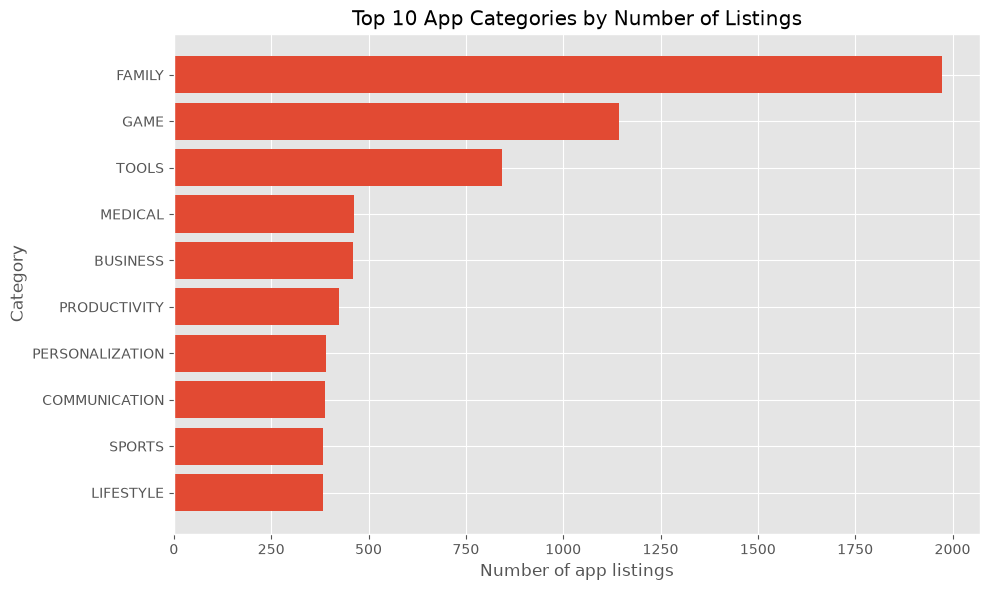

Observation 1: The chart ranks categories by the number of rows in the supplied apps file.
Observation 2: Category listing counts do not establish app quality, popularity or causal effects.


In [47]:
top_categories = category_summary.head(10).sort_values("app_count")
plt.figure(figsize=(10, 6))
plt.barh(top_categories.index.astype(str), top_categories["app_count"])
plt.title("Top 10 App Categories by Number of Listings")
plt.xlabel("Number of app listings")
plt.ylabel("Category")
plt.tight_layout()
plt.show()
print("Observation 1: The chart ranks categories by the number of rows in the supplied apps file.")
print("Observation 2: Category listing counts do not establish app quality, popularity or causal effects.")

## 9. Pivot Tables and Crosstab
### Task 3 — Pivot Tables and Crosstabulation
#### Subtask 3.1 — `pivot_table()`
A pivot table summarises a numerical measure across two categorical dimensions. The table below uses mean rating by category and price category; `margins=True` adds overall summaries.

In [14]:
rating_pivot = pd.pivot_table(
    apps, values="Rating_num", index="Category", columns="price_category",
    aggfunc="mean", margins=True, observed=False
)
display(rating_pivot.round(2))

price_category,Free,Paid,All
Category,,,
ART_AND_DESIGN,4.34,4.73,4.36
AUTO_AND_VEHICLES,4.18,4.60,4.19
BEAUTY,4.28,NaN,4.28
BOOKS_AND_REFERENCE,4.35,4.28,4.35
BUSINESS,4.12,4.20,4.12
COMICS,4.16,NaN,4.16
COMMUNICATION,4.17,4.06,4.16
DATING,3.98,3.62,3.97
EDUCATION,4.38,4.75,4.39


#### Subtask 3.2 — `crosstab()`
Crosstabulation counts combinations of two categorical variables. Row-normalisation expresses each category's distribution across content-rating groups as proportions.

In [15]:
content_crosstab = pd.crosstab(apps["Category"], apps["Content Rating"])
content_crosstab_prop = pd.crosstab(apps["Category"], apps["Content Rating"], normalize="index")
display(content_crosstab.head(12))
display(content_crosstab_prop.head(12).round(3))
print("Interpretation: counts show the number of listings in each combination; row-normalised values show within-category proportions.")

Content Rating,Adults only 18+,Everyone,Everyone 10+,Mature 17+,Teen,Unrated
Category,,,,,,
ART_AND_DESIGN,0,61,1,0,3,0
AUTO_AND_VEHICLES,0,83,1,0,1,0
BEAUTY,0,45,2,3,3,0
BOOKS_AND_REFERENCE,0,202,5,3,21,0
BUSINESS,0,445,1,1,13,0
COMICS,2,26,3,7,22,0
COMMUNICATION,0,345,0,10,32,0
DATING,0,21,0,201,12,0
EDUCATION,0,144,8,3,1,0


Content Rating,Adults only 18+,Everyone,Everyone 10+,Mature 17+,Teen,Unrated
Category,,,,,,
ART_AND_DESIGN,0.000,0.938,0.015,0.000,0.046,0.000
AUTO_AND_VEHICLES,0.000,0.976,0.012,0.000,0.012,0.000
BEAUTY,0.000,0.849,0.038,0.057,0.057,0.000
BOOKS_AND_REFERENCE,0.000,0.874,0.022,0.013,0.091,0.000
BUSINESS,0.000,0.967,0.002,0.002,0.028,0.000
COMICS,0.033,0.433,0.050,0.117,0.367,0.000
COMMUNICATION,0.000,0.891,0.000,0.026,0.083,0.000
DATING,0.000,0.090,0.000,0.859,0.051,0.000
EDUCATION,0.000,0.923,0.051,0.019,0.006,0.000


Interpretation: counts show the number of listings in each combination; row-normalised values show within-category proportions.


## 10. Data Reshaping
### Task 4 — Data Reshaping
**Concept:** Wide format stores several measured variables in separate columns. Long format stores a variable-name column and a value column. Reshaping supports plotting, tidy analysis and integration.

#### Subtask 4.1 — `melt()` (wide to long)
A small category summary is selected to keep the demonstration readable. `melt()` converts the rating and install measures into rows.

In [16]:
reshape_source = category_summary.head(6).reset_index()[["Category", "mean_rating", "mean_installs"]]
long_metrics = reshape_source.melt(
    id_vars="Category", value_vars=["mean_rating", "mean_installs"],
    var_name="metric", value_name="value"
)
display(reshape_source)
display(long_metrics)

,Category,mean_rating,mean_installs
0,FAMILY,4.192272,5.201959e+06
1,GAME,4.286326,3.066960e+07
2,TOOLS,4.047411,1.358573e+07
3,MEDICAL,4.189143,1.150269e+05
4,BUSINESS,4.121452,2.178076e+06
5,PRODUCTIVITY,4.211396,3.343418e+07


,Category,metric,value
0,FAMILY,mean_rating,4.192272e+00
1,GAME,mean_rating,4.286326e+00
2,TOOLS,mean_rating,4.047411e+00
3,MEDICAL,mean_rating,4.189143e+00
4,BUSINESS,mean_rating,4.121452e+00
5,PRODUCTIVITY,mean_rating,4.211396e+00
6,FAMILY,mean_installs,5.201959e+06
7,GAME,mean_installs,3.066960e+07
8,TOOLS,mean_installs,1.358573e+07
9,MEDICAL,mean_installs,1.150269e+05


#### Subtask 4.2 — `pivot()` (long to wide)
The category/metric combinations are unique in the melted demonstration, so `pivot()` can reshape them without aggregation.

In [17]:
wide_metrics = long_metrics.pivot(index="Category", columns="metric", values="value")
display(wide_metrics)

metric,mean_installs,mean_rating
Category,,
BUSINESS,2.178076e+06,4.121452
FAMILY,5.201959e+06,4.192272
GAME,3.066960e+07,4.286326
MEDICAL,1.150269e+05,4.189143
PRODUCTIVITY,3.343418e+07,4.211396
TOOLS,1.358573e+07,4.047411


#### Subtask 4.3 — `stack()` and `unstack()`
`stack()` moves a column level into the row index. `unstack()` reverses that operation. The example uses a compact pivot table; missing combinations may appear as NaN.

In [46]:
stacked_metrics = wide_metrics.stack()

display(stacked_metrics)

unstacked_metrics = stacked_metrics.unstack()

display(unstacked_metrics)

Category      metric       
BUSINESS      mean_installs    2.178076e+06
              mean_rating      4.121452e+00
FAMILY        mean_installs    5.201959e+06
              mean_rating      4.192272e+00
GAME          mean_installs    3.066960e+07
              mean_rating      4.286326e+00
MEDICAL       mean_installs    1.150269e+05
              mean_rating      4.189143e+00
PRODUCTIVITY  mean_installs    3.343418e+07
              mean_rating      4.211396e+00
TOOLS         mean_installs    1.358573e+07
              mean_rating      4.047411e+00
dtype: float64

metric,mean_installs,mean_rating
Category,,
BUSINESS,2.178076e+06,4.121452
FAMILY,5.201959e+06,4.192272
GAME,3.066960e+07,4.286326
MEDICAL,1.150269e+05,4.189143
PRODUCTIVITY,3.343418e+07,4.211396
TOOLS,1.358573e+07,4.047411


**Interpretation/decision:** `melt()` creates tidy long-form observations; `pivot()` restores a wide view when key combinations are unique. `stack()`/`unstack()` move levels between columns and the index, which is useful for MultiIndex summaries.

## 11. Data Integration
### Task 5 — Data Integration
### Task 6 — Integration Decision and Validation
#### Subtask 5.1/6.1 — Integration plan, keys and expected relationship
The complete Kaggle option contains an app table and a user-review table linked by `App`, with a one-to-many relationship (one app to many reviews). **The review CSV was not supplied**, so the actual app-review merge cannot be executed or validated. No review rows are fabricated.

To demonstrate integration using available evidence, create a category dimension from the app table: one row per `Category`, joined to many app rows. This is a many-to-one relationship from app listings to category dimension.

In [18]:
category_dimension = (
    apps[["Category"]].dropna().drop_duplicates()
    .assign(category_group=lambda x: x["Category"].str.replace("_", " ").str.title())
    .set_index("Category")
)
integration_plan = pd.DataFrame([
    ["apps (supplied)", "category_dimension (derived)", "Category", "Many-to-one", "Left", "Enrich each app listing with category label"],
    ["apps (full Kaggle option)", "googleplaystore_user_reviews.csv (not supplied)", "App", "One-to-many", "Left after review aggregation", "Attach app-level review summaries"]
], columns=["Left table", "Right table", "Key", "Expected relationship", "Intended join", "Purpose"])
display(integration_plan)
print("Category dimension rows:", len(category_dimension))
print("Category dimension key unique:", category_dimension.index.is_unique)

,Left table,Right table,Key,Expected relationship,Intended join,Purpose
0,apps (supplied),category_dimension (derived),Category,Many-to-one,Left,Enrich each app listing with category label
1,apps (full Kaggle option),googleplaystore_user_reviews.csv (not supplied),App,One-to-many,Left after review aggregation,Attach app-level review summaries


Category dimension rows: 34
Category dimension key unique: True


#### Subtask 5.2 — `merge()` and join types: inner, left, right and outer
The following demonstrations use the real derived category dimension. `indicator=True` identifies matched/unmatched records. `validate='many_to_one'` checks the expected relationship. Each join's retention behaviour is stated.
- **Inner:** keeps only rows with a matching category.
- **Left:** keeps every app listing; unmatched right-side values become missing.
- **Right:** keeps every category-dimension row, even if no app listing matches.
- **Outer:** keeps all keys from both sides.

In [19]:
apps_for_merge = apps.copy()
before_rows = len(apps_for_merge)
inner_merged = apps_for_merge.merge(category_dimension.reset_index(), on="Category", how="inner", validate="many_to_one", indicator=True, suffixes=("_app", "_dim"))
left_merged = apps_for_merge.merge(category_dimension.reset_index(), on="Category", how="left", validate="many_to_one", indicator=True, suffixes=("_app", "_dim"))
right_merged = apps_for_merge[["App", "Category"]].drop_duplicates().merge(category_dimension.reset_index(), on="Category", how="right", validate="many_to_one", indicator=True, suffixes=("_app", "_dim"))
outer_merged = apps_for_merge[["App", "Category"]].drop_duplicates().merge(category_dimension.reset_index(), on="Category", how="outer", validate="many_to_one", indicator=True, suffixes=("_app", "_dim"))
print("App rows before merge:", before_rows)
print("Inner rows:", len(inner_merged), "| Left rows:", len(left_merged), "| Right rows:", len(right_merged), "| Outer rows:", len(outer_merged))
display(left_merged[["App", "Category", "category_group", "_merge"]].head())
print("Left merge indicator counts:")
display(left_merged["_merge"].value_counts())

App rows before merge: 10841
Inner rows: 10841 | Left rows: 10841 | Right rows: 9745 | Outer rows: 9745


,App,Category,category_group,_merge
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,Art And Design,both
1,Coloring book moana,ART_AND_DESIGN,Art And Design,both
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,Art And Design,both
3,Sketch - Draw & Paint,ART_AND_DESIGN,Art And Design,both
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,Art And Design,both


Left merge indicator counts:


_merge
both          10841
left_only         0
right_only        0
Name: count, dtype: int64

#### Subtask 5.3 — Duplicate keys, suffixes and unmatched records
A duplicate key on the right side can multiply rows. The category dimension is deliberately deduplicated and validated. The `_merge` indicator counts matched and unmatched records. Suffixes resolve overlapping non-key names when both sides contain the same column name.

In [20]:
unmatched_left = left_merged.loc[left_merged["_merge"] == "left_only", "Category"].drop_duplicates()
unmatched_right = outer_merged.loc[outer_merged["_merge"] == "right_only", "Category"].drop_duplicates()
print("Matched app rows:", int((left_merged["_merge"] == "both").sum()))
print("Unmatched app rows:", int((left_merged["_merge"] == "left_only").sum()))
print("Unmatched category dimension keys:", len(unmatched_right))
print("Unmatched app-side categories:", unmatched_left.tolist())

Matched app rows: 10841
Unmatched app rows: 0
Unmatched category dimension keys: 0
Unmatched app-side categories: []


#### Subtask 5.4 — `join()` and index alignment
`DataFrame.join()` aligns rows using index labels by default. Here the app frame is indexed by `Category`, and the category dimension is also indexed by `Category`. `how='left'` preserves all app rows.

In [21]:
apps_indexed = apps.set_index("Category")
joined_apps = apps_indexed.join(category_dimension, how="left", rsuffix="_dimension")
print("Rows before join:", len(apps_indexed), "| Rows after join:", len(joined_apps))
display(joined_apps[["App", "category_group"]].head())

Rows before join: 10841 | Rows after join: 10841


,App,category_group
Category,,
ART_AND_DESIGN,Photo Editor & Candy Camera & Grid & ScrapBook,Art And Design
ART_AND_DESIGN,Coloring book moana,Art And Design
ART_AND_DESIGN,"U Launcher Lite – FREE Live Cool Themes, Hide ...",Art And Design
ART_AND_DESIGN,Sketch - Draw & Paint,Art And Design
ART_AND_DESIGN,Pixel Draw - Number Art Coloring Book,Art And Design


#### Subtask 5.5 — `concat()`
`concat()` stacks DataFrames along an axis. The app table is split into two row partitions and concatenated back. This is a demonstration of combining same-schema extracts, not a second source table.

In [22]:
split_point = len(apps) // 2
apps_part_1 = apps.iloc[:split_point].copy()
apps_part_2 = apps.iloc[split_point:].copy()
apps_concatenated = pd.concat([apps_part_1, apps_part_2], axis=0, ignore_index=True)
print("Original rows:", len(apps), "| Concatenated rows:", len(apps_concatenated))
print("Same app-name sequence after concatenation:", apps_concatenated["App"].reset_index(drop=True).equals(apps["App"].reset_index(drop=True)))

Original rows: 10841 | Concatenated rows: 10841
Same app-name sequence after concatenation: True


#### Subtask 6.2 — Row-count validation and row multiplication
A one-to-many merge can increase rows because one parent key matches several child rows. If app rows were merged directly with multiple review rows, each app could appear once per review; app-level totals would then be inflated. The safe approach is to aggregate reviews to one row per app before joining to app-level statistics. This cannot be performed here because the review CSV is absent.

**Integration decision:** The category-dimension left merge is many-to-one and should preserve app-row count. The category dimension is unique by construction; merge validation confirms this. The review integration is documented as a limitation rather than simulated as real data.

In [23]:
print("Expected app rows:", len(apps))
print("Actual category left-merge rows:", len(left_merged))
print("Row count preserved:", len(left_merged) == len(apps))
print("Category dimension duplicate keys:", category_dimension.index.duplicated().sum())
print("App table row multiplication avoided: aggregate any one-to-many child table to App before app-level joining.")

Expected app rows: 10841
Actual category left-merge rows: 10841
Row count preserved: True
Category dimension duplicate keys: 0
App table row multiplication avoided: aggregate any one-to-many child table to App before app-level joining.


## 12. Descriptive Statistics
### Task 7 — Measures of Central Tendency
#### Subtask 7.1 — Mean, median and mode
The mean is sensitive to extreme values; the median is the middle sorted observation; the mode is the most frequent value. Two suitable numerical variables are rating and install count. Install counts are strongly affected by the dataset's range labels and conversion, so interpret them cautiously.

In [24]:
central_rows = []
for col in ["Rating_num", "Installs_num"]:
    series = apps[col].dropna()
    modes = series.mode()
    central_rows.append({
        "Variable": col, "Mean": series.mean(), "Median": series.median(),
        "Mode(s)_first": modes.iloc[0] if len(modes) else np.nan,
        "Mode_count": len(modes), "N": len(series)
    })
central_tendency = pd.DataFrame(central_rows).set_index("Variable")
display(central_tendency)

,Mean,Median,Mode(s)_first,Mode_count,N
Variable,,,,,
Rating_num,4.193338e+00,4.3,4.4,1,9367
Installs_num,1.546434e+07,100000.0,1000000.0,1,10840


**Interpretation:** Compare mean and median for each variable. A substantially larger mean than median often indicates a longer right tail; the reverse can indicate left skew. Mode can be non-unique, particularly for discretised values.

### Task 8 — Measures of Dispersion
#### Subtask 8.1 — Variance, standard deviation and range
Variance and standard deviation describe spread around the mean; range is maximum minus minimum. Sample variance/standard deviation (`ddof=1`) are used for these descriptive estimates. Standard deviation and range use the variable's original units; variance uses squared units.

In [25]:
dispersion_rows = []
for col in ["Rating_num", "Installs_num"]:
    s = apps[col].dropna()
    dispersion_rows.append({
        "Variable": col, "Variance_sample": s.var(ddof=1),
        "Std_dev_sample": s.std(ddof=1), "Minimum": s.min(),
        "Maximum": s.max(), "Range": s.max() - s.min(), "Units": "rating points" if col == "Rating_num" else "installs"
    })
dispersion = pd.DataFrame(dispersion_rows).set_index("Variable")
display(dispersion)

,Variance_sample,Std_dev_sample,Minimum,Maximum,Range,Units
Variable,,,,,,
Rating_num,2.888324e-01,5.374313e-01,1.0,1.900000e+01,1.800000e+01,rating points
Installs_num,7.229992e+15,8.502936e+07,0.0,1.000000e+09,1.000000e+09,installs


### Task 9 — Percentiles, Quantiles and Five-Number Summary
#### Subtask 9.1 — Selected percentiles and five-number summary
Percentiles locate values below which a given percentage of observations fall. Quartiles divide ordered observations into four parts. The IQR (`Q3 − Q1`) describes the middle 50%.

In [26]:
percentile_report = {}
five_number_rows = []
for col in ["Rating_num", "Installs_num"]:
    s = apps[col].dropna()
    percentile_report[col] = s.quantile([0.10, 0.25, 0.50, 0.75, 0.90])
    q1, med, q3 = s.quantile([0.25, 0.50, 0.75])
    five_number_rows.append({"Variable": col, "Minimum": s.min(), "Q1": q1, "Median": med, "Q3": q3, "Maximum": s.max(), "IQR": q3-q1})
display(pd.DataFrame(percentile_report).rename(index={0.1:"10th",0.25:"25th",0.5:"50th",0.75:"75th",0.9:"90th"}))
display(pd.DataFrame(five_number_rows).set_index("Variable"))

,Rating_num,Installs_num
10th,3.6,100.0
25th,4.0,1000.0
50th,4.3,100000.0
75th,4.5,5000000.0
90th,4.7,10000000.0


,Minimum,Q1,Median,Q3,Maximum,IQR
Variable,,,,,,
Rating_num,1.0,4.0,4.3,4.5,1.900000e+01,0.5
Installs_num,0.0,1000.0,100000.0,5000000.0,1.000000e+09,4999000.0


### Task 10 — Skewness and Kurtosis
#### Subtask 10.1 — Calculate and interpret
Positive skew has a longer right tail; negative skew has a longer left tail; values near zero suggest approximate symmetry but should be interpreted with a plot. Pandas reports **Fisher/excess kurtosis** (normal reference approximately zero), not Pearson kurtosis (normal reference approximately three). Kurtosis relates to tail/extreme-value behaviour and is not simply a measure of peakedness.

In [27]:
shape_stats = pd.DataFrame({
    col: {
        "skewness": apps[col].dropna().skew(),
        "excess_kurtosis_fisher": apps[col].dropna().kurt()
    } for col in ["Rating_num", "Installs_num", "Reviews_num", "Price_num"]
}).T
display(shape_stats)

,skewness,excess_kurtosis_fisher
Rating_num,0.595637,65.994781
Installs_num,9.572067,100.280006
Reviews_num,16.449584,341.060356
Price_num,23.707392,578.142998


**Practical implications:** For strongly skewed variables, median and quantiles may describe a typical app better than the mean. Heavy tails motivate careful outlier inspection. Distribution shape also affects whether normal-based methods and the empirical rule are suitable.

## 13. Distribution Analysis
### Task 11 — Common Distributions
#### Subtask 11.1 — Histograms, density curves and box plots
Inspect real variables rather than forcing a distribution label. App ratings are bounded between 1 and 5 and may cluster near high values; installs, reviews and prices can be highly right-skewed. A real approximately normal, negatively skewed or bimodal variable may not be present. Controlled examples below are clearly marked as simulated.

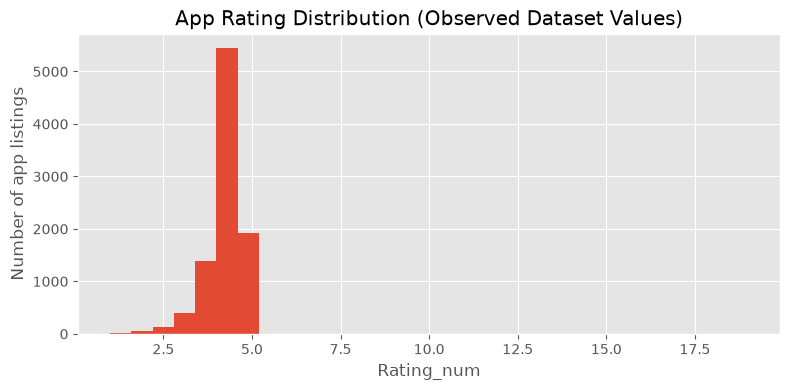

Observation 1: Rating_num is plotted using observed values only.
Observation 2: Skewness = 0.596; use the histogram and skewness together when describing shape.


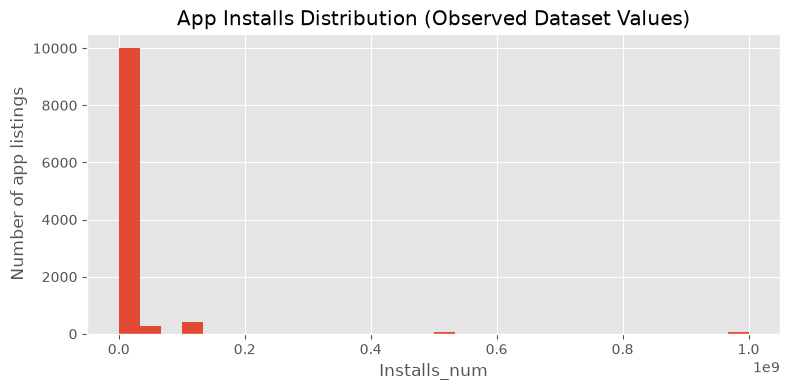

Observation 1: Installs_num is plotted using observed values only.
Observation 2: Skewness = 9.572; use the histogram and skewness together when describing shape.


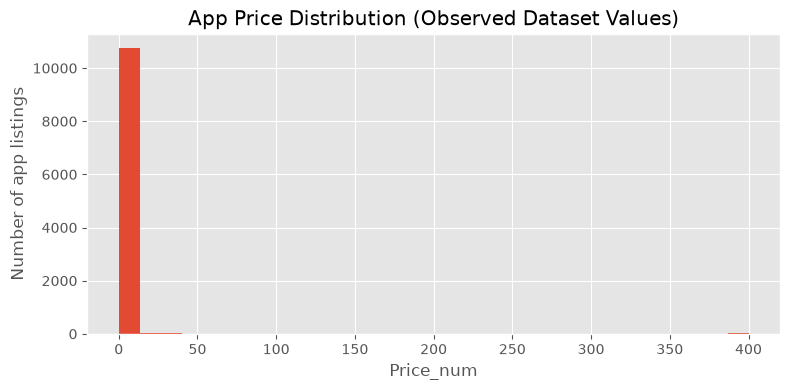

Observation 1: Price_num is plotted using observed values only.
Observation 2: Skewness = 23.707; use the histogram and skewness together when describing shape.


In [28]:
for col, title in [("Rating_num", "App Rating Distribution"), ("Installs_num", "App Installs Distribution"), ("Price_num", "App Price Distribution")]:
    plt.figure(figsize=(8, 4))
    plt.hist(apps[col].dropna(), bins=30)
    plt.title(title + " (Observed Dataset Values)")
    plt.xlabel(col)
    plt.ylabel("Number of app listings")
    plt.tight_layout()
    plt.show()
    print(f"Observation 1: {col} is plotted using observed values only.")
    print(f"Observation 2: Skewness = {apps[col].dropna().skew():.3f}; use the histogram and skewness together when describing shape.")

#### Subtask 11.2 — Controlled distribution-shape demonstrations (simulated)
If the real dataset does not provide clear examples of all requested shapes, controlled simulations demonstrate normal, positive-skew, negative-skew and bimodal shapes. These values are **not Google Play observations**.

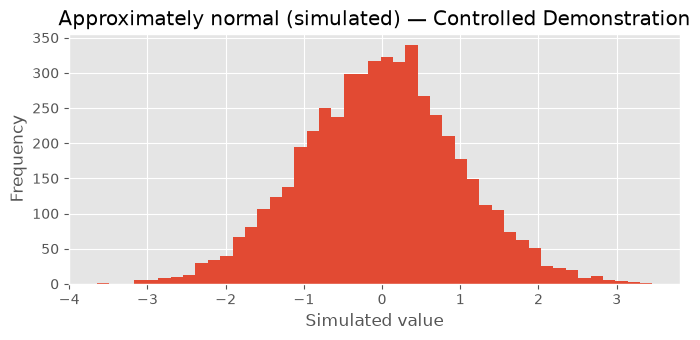

Approximately normal (simulated) | skewness: 0.002


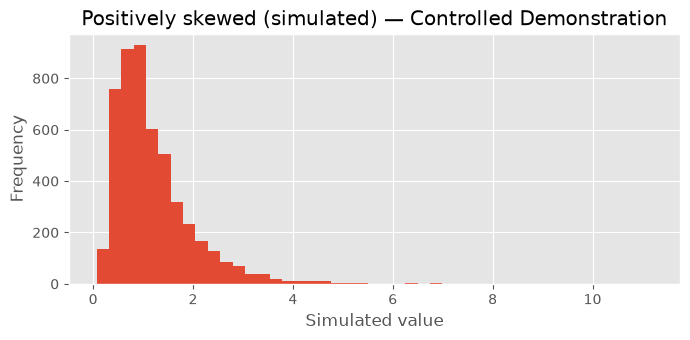

Positively skewed (simulated) | skewness: 2.401


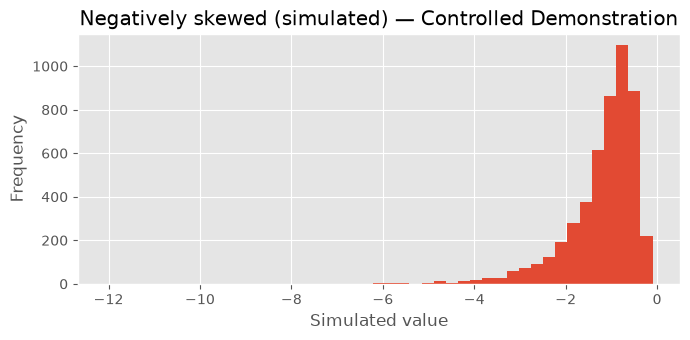

Negatively skewed (simulated) | skewness: -2.374


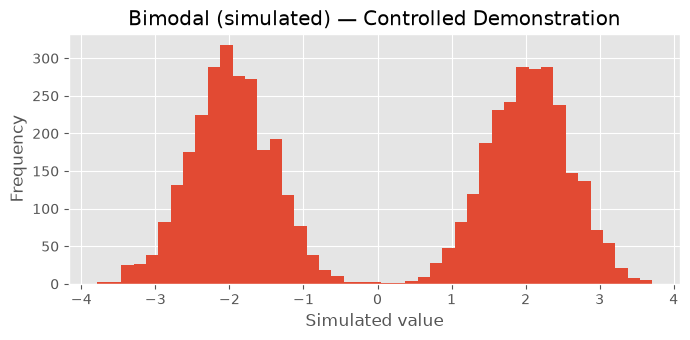

Bimodal (simulated) | skewness: 0.001


In [29]:
rng = np.random.default_rng(RANDOM_SEED)
simulated_shapes = {
    "Approximately normal (simulated)": rng.normal(0, 1, 5000),
    "Positively skewed (simulated)": rng.lognormal(0, 0.6, 5000),
    "Negatively skewed (simulated)": -rng.lognormal(0, 0.6, 5000),
    "Bimodal (simulated)": np.r_[rng.normal(-2, 0.55, 2500), rng.normal(2, 0.55, 2500)]
}
for label, values in simulated_shapes.items():
    plt.figure(figsize=(7, 3.5))
    plt.hist(values, bins=45)
    plt.title(label + " — Controlled Demonstration")
    plt.xlabel("Simulated value")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()
    print(label, "| skewness:", round(pd.Series(values).skew(), 3))

**Interpretation:** A normal distribution is approximately symmetric and single-peaked; positive/negative skew have longer right/left tails; a bimodal distribution has two visible peaks and may reflect mixed subpopulations. The simulated examples explain shape only and are not used in app-level findings.

## 14. Empirical Rule
### Task 12 — Empirical Rule (68–95–99.7 Rule)
For an approximately normal, bell-shaped distribution, about 68% of observations lie within mean ± 1 SD, 95% within ± 2 SD and 99.7% within ± 3 SD. The real app variables are bounded or skewed, so the rule may not fit. A labelled normal simulation is used for a controlled comparison, alongside observed app ratings.

,within_1_sd_percent,within_2_sd_percent,within_3_sd_percent
Dataset,,,
Normal simulation (not app data),68.00,95.27,99.81
Observed app ratings,82.21,95.30,98.39


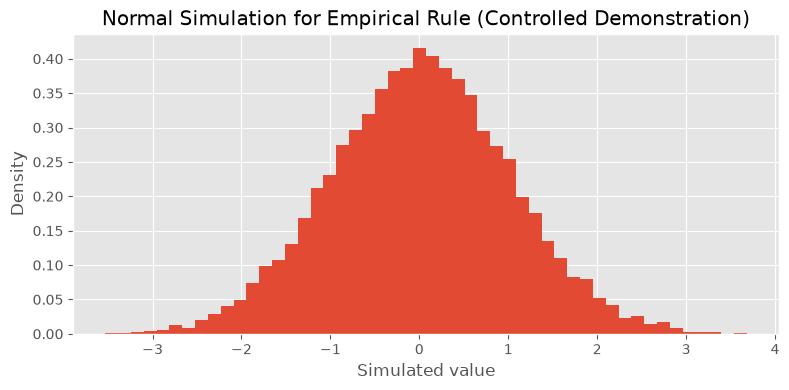

Observation 1: Compare the simulated percentages with 68%, 95% and 99.7%.
Observation 2: The rating distribution is bounded and may depart from the normal-rule percentages.


In [30]:
def empirical_rule_percentages(series):
    x = pd.Series(series).dropna()
    mu, sd = x.mean(), x.std(ddof=0)
    return {f"within_{k}_sd_percent": ((x >= mu-k*sd) & (x <= mu+k*sd)).mean()*100 for k in [1,2,3]}

normal_sim = rng.normal(0, 1, 10000)
empirical_results = pd.DataFrame([
    {"Dataset": "Normal simulation (not app data)", **empirical_rule_percentages(normal_sim)},
    {"Dataset": "Observed app ratings", **empirical_rule_percentages(apps["Rating_num"])}
]).set_index("Dataset")
display(empirical_results.round(2))
plt.figure(figsize=(8, 4))
plt.hist(normal_sim, bins=50, density=True)
plt.title("Normal Simulation for Empirical Rule (Controlled Demonstration)")
plt.xlabel("Simulated value")
plt.ylabel("Density")
plt.tight_layout()
plt.show()
print("Observation 1: Compare the simulated percentages with 68%, 95% and 99.7%.")
print("Observation 2: The rating distribution is bounded and may depart from the normal-rule percentages.")

**Decision:** The empirical rule is presented as a property of approximately normal distributions, not as a universal rule for all app variables. Skewed, heavy-tailed or bimodal distributions violate its shape assumptions.

## 15. Sampling and Central Limit Theorem
### Task 13 — Sampling and CLT
#### Subtask 13.1 — Population, sample and sampling variability
For this analysis, the available app rows form the source population. A sample is a subset selected for analysis. Sampling variability is the natural change in a statistic across different random samples. The sampling method below is simple random sampling without replacement within each repetition; a fixed seed makes the experiment reproducible.

In [33]:
population = apps["Installs_num"].dropna().to_numpy()
print("Source population size for installs:", len(population))
print("Population mean:", population.mean())
print("Sampling method: simple random sample without replacement within each repetition.")

Source population size for installs: 10840
Population mean: 15464338.882564576
Sampling method: simple random sample without replacement within each repetition.


#### Subtask 13.2 — Repeated samples and sampling distribution
Draw 1,000 samples of size 30 and calculate each sample mean. Compare the distribution of means at multiple sample sizes. The CLT says the sampling distribution of the mean tends to become more nearly normal as sample size increases under its conditions; standard error generally decreases as n increases.

,mean_of_sample_means,std_of_sample_means
n=10,1.670367e+07,2.823983e+07
n=30,1.615930e+07,1.675188e+07
n=50,1.533258e+07,1.218305e+07


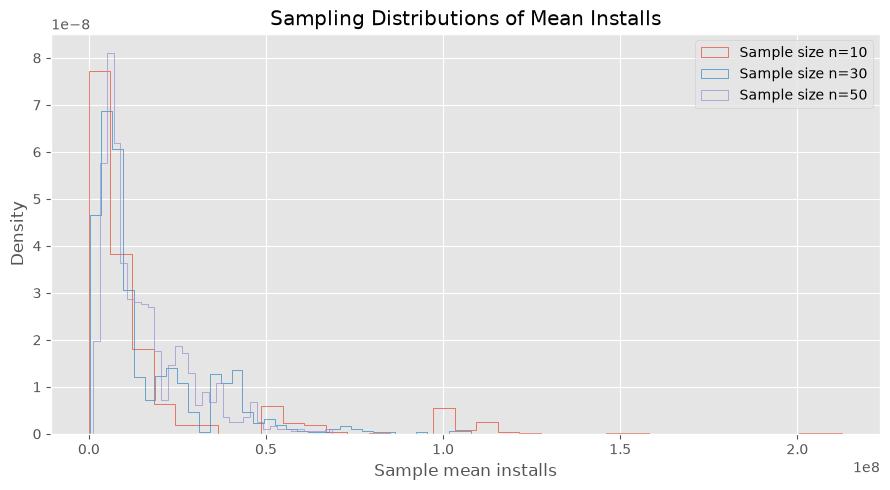

Repetitions per sample size: 1000; fixed random seed: 42.
Observation 1: The means cluster around the source-population mean.
Observation 2: The spread of sample means generally decreases as sample size increases.


In [34]:
rng = np.random.default_rng(42)
repetitions = 1000
sample_sizes = [10, 30, 50]
sampling_means = {}
for n in sample_sizes:
    means = [rng_sampling.choice(population, size=n, replace=False).mean() for _ in range(repetitions)]
    sampling_means[n] = np.array(means)

sampling_summary = pd.DataFrame({
    f"n={n}": {"mean_of_sample_means": values.mean(), "std_of_sample_means": values.std(ddof=1)}
    for n, values in sampling_means.items()
}).T
display(sampling_summary)
plt.figure(figsize=(9, 5))
for n, values in sampling_means.items():
    plt.hist(values, bins=35, density=True, histtype="step", label=f"Sample size n={n}")
plt.title("Sampling Distributions of Mean Installs")
plt.xlabel("Sample mean installs")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Repetitions per sample size: {repetitions}; fixed random seed: {RANDOM_SEED}.")
print("Observation 1: The means cluster around the source-population mean.")
print("Observation 2: The spread of sample means generally decreases as sample size increases.")

**Limitations:** Install counts are extremely skewed and may contain extreme values. Sampling without replacement is from the available finite dataset; the CLT approximation can require larger samples for strongly skewed populations. These sample results describe the supplied dataset, not all apps in the Play Store.

## 16. Correlation Analysis
### Task 14 — Covariance and Correlation
#### Subtask 14.1 — Covariance, Pearson and Spearman
Covariance indicates whether two variables tend to move together, but its magnitude depends on their units and scales. Pearson correlation measures linear association; Spearman correlation measures monotonic rank association. Both correlations range from −1 to +1.

In [35]:
corr_vars = apps[["Rating_num", "Reviews_num", "Installs_num", "Price_num", "Size_num_mb"]].copy()
covariance_matrix = corr_vars.cov()
pearson_matrix = corr_vars.corr(method="pearson")
spearman_matrix = corr_vars.corr(method="spearman")
display(covariance_matrix)
display(pearson_matrix.round(3))
display(spearman_matrix.round(3))

,Rating_num,Reviews_num,Installs_num,Price_num,Size_num_mb
Rating_num,2.888324e-01,1.103803e+05,2.414057e+06,-1.784901e-01,1.069130e+00
Reviews_num,1.103803e+05,8.571782e+12,1.601024e+14,-4.514314e+05,9.234977e+06
Installs_num,2.414057e+06,1.601024e+14,7.229992e+15,-1.585318e+07,1.719503e+08
Price_num,-1.784901e-01,-4.514314e+05,-1.585318e+07,2.543930e+02,-9.020008e+00
Size_num_mb,1.069130e+00,9.234977e+06,1.719503e+08,-9.020008e+00,5.102667e+02


,Rating_num,Reviews_num,Installs_num,Price_num,Size_num_mb
Rating_num,1.000,0.068,0.051,-0.022,0.084
Reviews_num,0.068,1.000,0.643,-0.010,0.238
Installs_num,0.051,0.643,1.000,-0.012,0.165
Price_num,-0.022,-0.010,-0.012,1.000,-0.023
Size_num_mb,0.084,0.238,0.165,-0.023,1.000


,Rating_num,Reviews_num,Installs_num,Price_num,Size_num_mb
Rating_num,1.000,0.156,0.070,0.064,0.069
Reviews_num,0.156,1.000,0.971,-0.171,0.367
Installs_num,0.070,0.971,1.000,-0.243,0.348
Price_num,0.064,-0.171,-0.243,1.000,-0.054
Size_num_mb,0.069,0.367,0.348,-0.054,1.000


#### Subtask 14.2 — Correlation heatmap
The heatmap displays the Pearson correlation matrix with labelled variables and a fixed scale from −1 to +1.

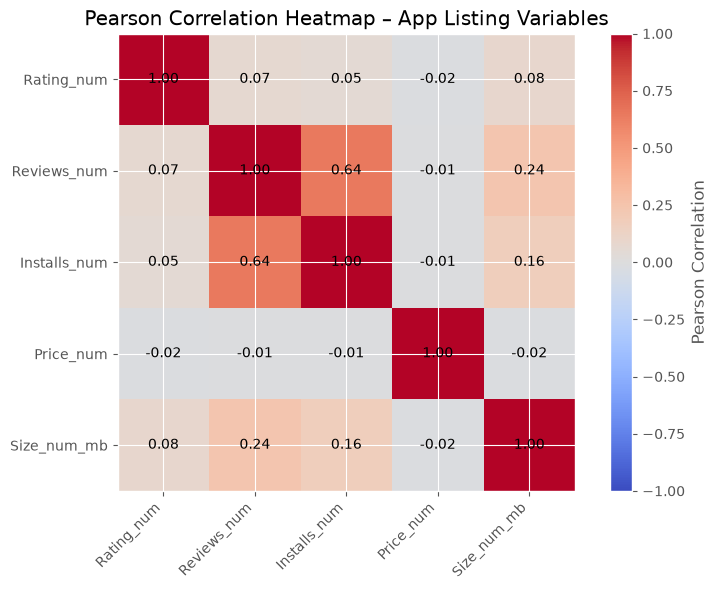

Observation 1: Values near +1 indicate strong positive linear association; values near -1 indicate strong negative association.
Observation 2: Values near 0 indicate weak linear association, not necessarily absence of a nonlinear relationship.


In [37]:
plt.figure(figsize=(8, 6))

plt.imshow(pearson_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Pearson Correlation")

plt.xticks(
    range(len(pearson_matrix.columns)),
    pearson_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(pearson_matrix.index)),
    pearson_matrix.index
)

for i in range(len(pearson_matrix.index)):
    for j in range(len(pearson_matrix.columns)):
        plt.text(
            j, i,
            f"{pearson_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Pearson Correlation Heatmap – App Listing Variables")
plt.tight_layout()
plt.show()

print("Observation 1: Values near +1 indicate strong positive linear association; values near -1 indicate strong negative association.")
print("Observation 2: Values near 0 indicate weak linear association, not necessarily absence of a nonlinear relationship.")

#### Subtask 14.3 — Scatter plots and Pearson/Spearman comparison
Scatter plots reveal shape, clusters and extreme points that a single coefficient may hide. The selected pairs use numeric app attributes. Interpret association only; do not make causal claims.

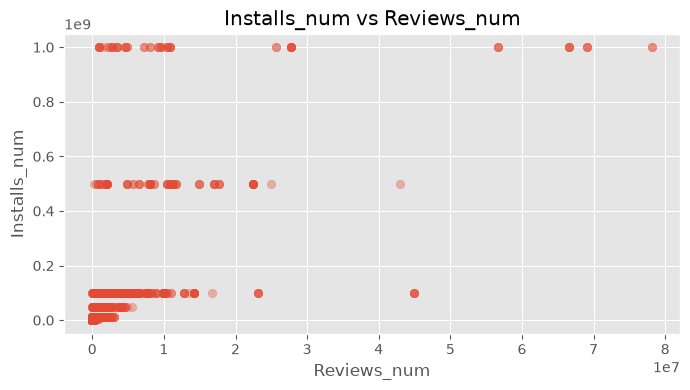

Reviews_num vs Installs_num: Pearson=0.643; Spearman=0.971


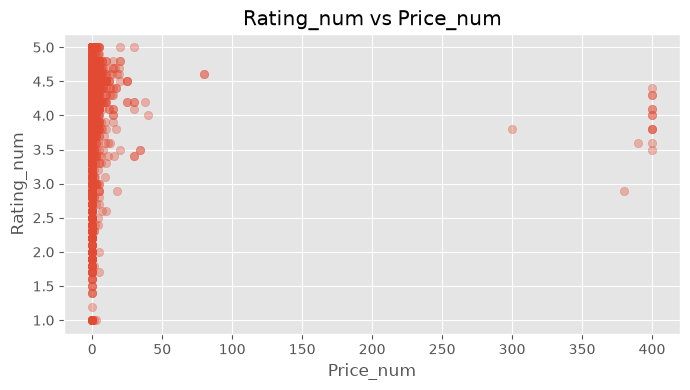

Price_num vs Rating_num: Pearson=-0.022; Spearman=0.064


In [40]:
for x_col, y_col in [("Reviews_num", "Installs_num"), ("Price_num", "Rating_num")]:
    plot_data = apps[[x_col, y_col]].dropna()
    plt.figure(figsize=(7, 4))
    plt.scatter(plot_data[x_col], plot_data[y_col], alpha=0.35)
    plt.title(f"{y_col} vs {x_col}")
    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.tight_layout()
    plt.show()
    print(f"{x_col} vs {y_col}: Pearson={plot_data[x_col].corr(plot_data[y_col], method='pearson'):.3f}; Spearman={plot_data[x_col].corr(plot_data[y_col], method='spearman'):.3f}")

**Interpretation:** If Pearson and Spearman differ, the association may be monotonic but nonlinear, influenced by outliers, or better represented by ranks than raw magnitudes. Correlation does not prove causation: confounding variables, reverse relationships, selection effects or coincidence may explain an association. No causal claim is made in this notebook.

## 17. Outlier Detection and Treatment
### Task 15 — Outlier Detection
#### Subtask 15.1 — Box plot and IQR method
For a numerical variable, IQR = Q3 − Q1; lower fence = Q1 − 1.5 × IQR; upper fence = Q3 + 1.5 × IQR. Values outside these fences are potential outliers, not automatically errors.

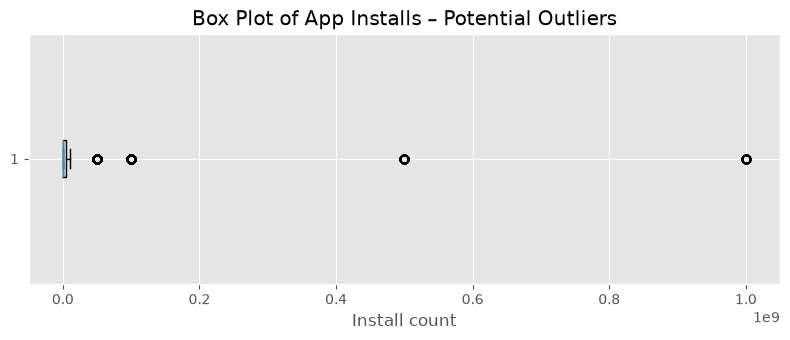

Q1: 1000.0 | Q3: 5000000.0 | IQR: 4999000.0
Lower fence: -7497500.0 | Upper fence: 12498500.0
IQR potential outliers: 828 (7.64%)


,App,Installs,Installs_num,Category
3,Sketch - Draw & Paint,"50,000,000+",5.000000e+07,ART_AND_DESIGN
139,Wattpad 📖 Free Books,"100,000,000+",1.000000e+08,BOOKS_AND_REFERENCE
143,Amazon Kindle,"100,000,000+",1.000000e+08,BOOKS_AND_REFERENCE
152,Google Play Books,"1,000,000,000+",1.000000e+09,BOOKS_AND_REFERENCE
188,Indeed Job Search,"50,000,000+",5.000000e+07,BUSINESS
192,Docs To Go™ Free Office Suite,"50,000,000+",5.000000e+07,BUSINESS
194,OfficeSuite : Free Office + PDF Editor,"100,000,000+",1.000000e+08,BUSINESS
201,Facebook Pages Manager,"50,000,000+",5.000000e+07,BUSINESS
225,Secure Folder,"50,000,000+",5.000000e+07,BUSINESS
292,Docs To Go™ Free Office Suite,"50,000,000+",5.000000e+07,BUSINESS


In [39]:
outlier_variable = "Installs_num"
outlier_series = apps[outlier_variable].dropna()

q1, q3 = outlier_series.quantile([0.25, 0.75])
iqr_value = q3 - q1

lower_fence = q1 - 1.5 * iqr_value
upper_fence = q3 + 1.5 * iqr_value

iqr_mask = (outlier_series < lower_fence) | (outlier_series > upper_fence)

# Matplotlib box plot (replaces sns.boxplot)
plt.figure(figsize=(8, 3.5))
plt.boxplot(outlier_series, vert=False)
plt.title("Box Plot of App Installs – Potential Outliers")
plt.xlabel("Install count")
plt.tight_layout()
plt.show()

print("Q1:", q1, "| Q3:", q3, "| IQR:", iqr_value)
print("Lower fence:", lower_fence, "| Upper fence:", upper_fence)
print("IQR potential outliers:", int(iqr_mask.sum()), f"({iqr_mask.mean()*100:.2f}%)")

display(
    apps.loc[
        iqr_mask[iqr_mask].index,
        ["App", "Installs", "Installs_num", "Category"]
    ].head(10)
)

#### Subtask 15.2 — Z-score method
A common exploratory threshold is absolute Z-score greater than 3. Z-scores are most interpretable when distribution assumptions are considered; a highly skewed variable such as installs can produce misleading flags. The comparison below uses the same non-missing install values.

In [41]:
install_mean = outlier_series.mean()
install_sd = outlier_series.std(ddof=0)
install_z = (outlier_series - install_mean) / install_sd
z_threshold = 3
z_mask = install_z.abs() > z_threshold
print("Z-score threshold: |Z| >", z_threshold)
print("Z-score potential outliers:", int(z_mask.sum()), f"({z_mask.mean()*100:.2f}%)")
outlier_comparison = pd.DataFrame({
    "Method": ["IQR", "Z-score"],
    "Count": [int(iqr_mask.sum()), int(z_mask.sum())],
    "Percent": [iqr_mask.mean()*100, z_mask.mean()*100]
})
display(outlier_comparison.round(2))

Z-score threshold: |Z| > 3
Z-score potential outliers: 130 (1.20%)


,Method,Count,Percent
0,IQR,828,7.64
1,Z-score,130,1.20


#### Subtask 15.3 — Inspect unusual observations
Inspect original install strings, app names and categories before deciding. Large install values may be legitimate for popular apps. IQR and Z-score can flag different records because they use different definitions and distribution assumptions.

In [42]:
flagged_union = iqr_mask.index[iqr_mask | z_mask.reindex(iqr_mask.index, fill_value=False)]
display(apps.loc[flagged_union, ["App", "Category", "Installs", "Installs_num", "Reviews", "Rating_num"]].sort_values("Installs_num", ascending=False).head(20))
print("IQR-only:", int((iqr_mask & ~z_mask).sum()))
print("Z-score-only:", int((z_mask & ~iqr_mask).sum()))
print("Flagged by both:", int((iqr_mask & z_mask).sum()))

,App,Category,Installs,Installs_num,Reviews,Rating_num
3234,Google,TOOLS,"1,000,000,000+",1.000000e+09,8033493,4.4
3665,YouTube,VIDEO_PLAYERS,"1,000,000,000+",1.000000e+09,25655305,4.3
4096,Gmail,COMMUNICATION,"1,000,000,000+",1.000000e+09,4604324,4.3
3687,Google Play Movies & TV,VIDEO_PLAYERS,"1,000,000,000+",1.000000e+09,906384,3.7
3232,Google Street View,TRAVEL_AND_LOCAL,"1,000,000,000+",1.000000e+09,2129707,4.2
5395,Google Photos,PHOTOGRAPHY,"1,000,000,000+",1.000000e+09,10847682,4.5
3223,Maps - Navigate & Explore,TRAVEL_AND_LOCAL,"1,000,000,000+",1.000000e+09,9235373,4.3
468,Skype - free IM & video calls,COMMUNICATION,"1,000,000,000+",1.000000e+09,10484169,4.1
464,Hangouts,COMMUNICATION,"1,000,000,000+",1.000000e+09,3419513,4.0
3736,Google News,NEWS_AND_MAGAZINES,"1,000,000,000+",1.000000e+09,877635,3.9


IQR-only: 698
Z-score-only: 0
Flagged by both: 130


### Task 16 — Outlier Handling Strategies
#### Subtask 16.1 — Removal, capping and retention
Keep original values unchanged. Each strategy is applied to a separate derived series. Removal is justified only for confirmed errors or values outside the target population; capping limits influence while retaining rows; retention is appropriate when extremes are genuine and meaningful. Here high install counts may be legitimate, so retention is the primary analytical decision.

In [43]:
# Separate copies for three strategies; original apps['Installs_num'] is not modified.
installs_original = outlier_series.copy()
installs_removed = installs_original.loc[~iqr_mask].copy()
installs_capped = installs_original.clip(lower=lower_fence, upper=upper_fence)
installs_retained = installs_original.copy()

def summary_stats(s):
    return pd.Series({
        "count": s.count(), "mean": s.mean(), "median": s.median(),
        "std_dev": s.std(ddof=1), "range": s.max() - s.min()
    })

treatment_comparison = pd.DataFrame({
    "Original": summary_stats(installs_original),
    "Removal_IQR": summary_stats(installs_removed),
    "Capping_IQR": summary_stats(installs_capped),
    "Retention": summary_stats(installs_retained)
}).T
display(treatment_comparison)

,count,mean,median,std_dev,range
Original,10840.0,1.546434e+07,100000.0,8.502936e+07,1.000000e+09
Removal_IQR,10012.0,1.826152e+06,100000.0,3.349851e+06,1.000000e+07
Capping_IQR,10840.0,2.641346e+06,100000.0,4.289582e+06,1.249850e+07
Retention,10840.0,1.546434e+07,100000.0,8.502936e+07,1.000000e+09


**Decision and conclusion:** The removal copy demonstrates the effect of excluding IQR-flagged observations; it is not adopted as the default dataset because extreme install counts may be genuine. The capped copy demonstrates a sensitivity treatment, but capping changes the upper-tail distribution. Retention preserves valid rare cases and is the preferred default unless a source value is verified as erroneous. Original values remain unchanged.

## 18. Data Visualisation and Interpretation
### Mandatory visualisation checklist
The notebook has generated:
- Histogram(s) for numerical distributions and empirical-rule discussion.
- Box plot for spread, quartiles and potential outliers.
- Scatter plots for numerical relationships used in correlation analysis.
- Bar/comparison chart for category listing counts.
- Correlation heatmap for numerical variables.
- Sampling-distribution plot for repeated sample means.

Every chart has a meaningful title and labelled axes. At least two observations are printed immediately below each required chart. Plots are generated by notebook code, not screenshots.

## 19. Findings and Observations
The following summary is calculated from the supplied file at execution time. It deliberately reports data-derived quantities rather than hard-coded claims.

In [44]:
findings = {
    "app_listing_rows": len(apps),
    "columns": raw_df.shape[1],
    "unique_app_names": raw_df["App"].nunique(),
    "categories": raw_df["Category"].nunique(),
    "missing_rating_rows": apps["Rating_num"].isna().sum(),
    "median_rating": apps["Rating_num"].median(),
    "median_installs": apps["Installs_num"].median(),
    "free_app_share_percent": apps["price_category"].eq("Free").mean() * 100,
    "IQR_install_outlier_count": int(iqr_mask.sum()),
    "Zscore_install_outlier_count": int(z_mask.sum())
}
display(pd.Series(findings, name="Observed result").to_frame())
print("Observation 1: The dataset has repeated app names; app-name key uniqueness must not be assumed.")
print("Observation 2: Ratings and install counts have different scales and distribution shapes; use variable-appropriate summaries.")
print("Observation 3: The review file is absent, so conclusions are restricted to app-listing attributes.")

,Observed result
app_listing_rows,10841.000000
columns,13.000000
unique_app_names,9660.000000
categories,34.000000
missing_rating_rows,1474.000000
median_rating,4.300000
median_installs,100000.000000
free_app_share_percent,92.611383
IQR_install_outlier_count,828.000000
Zscore_install_outlier_count,130.000000


Observation 1: The dataset has repeated app names; app-name key uniqueness must not be assumed.
Observation 2: Ratings and install counts have different scales and distribution shapes; use variable-appropriate summaries.
Observation 3: The review file is absent, so conclusions are restricted to app-listing attributes.


## 20. Limitations and Future Scope
### Limitations
- Only `googleplaystore.csv` was supplied. The Kaggle user-review CSV and licence text file were not included.
- App names are repeated, so `App` is not a unique key in the raw listing file.
- The dataset is a snapshot and may not represent the current Google Play Store.
- Install counts are stored as ranges (for example, `10,000+`); parsing the lower numeric bound treats the displayed minimum as a numeric proxy, not an exact install count.
- `Size` includes `Varies with device`; those values cannot be converted to a single numeric size.
- Ratings and other fields contain missing or potentially malformed values.
- The dataset is observational; correlations do not establish causation.
- Simulated distribution examples are teaching demonstrations, not observed app records.

### Future scope
- Download and inspect the companion review CSV; aggregate review sentiment by app before merging to avoid one-to-many row multiplication.
- Validate app-name spelling and define a defensible app-level deduplication rule.
- Verify the Kaggle licence and document its exact terms.
- Analyse update recency, app version compatibility and category-specific pricing with domain context.
- Consider robust statistics or transformations for highly skewed install/review variables.

## 21. Final Conclusion
This project applied the Unit IV and Unit V EDA workflow to the supplied Google Play Store app listings. It retained the raw data, assessed data quality, engineered analysis-ready features, compared categories, demonstrated Pandas grouping and reshaping, and integrated the app data with a derived category dimension using validated keys and row-count checks. It calculated descriptive statistics, examined distributions, demonstrated the empirical rule and CLT, measured correlations, and compared IQR/Z-score outlier strategies.

The analysis is limited to app-listing attributes because the companion review file was not supplied. Results should therefore be interpreted as patterns in this particular dataset snapshot, not as causal explanations or statements about every app currently available on Google Play.